# H&M Customer Segmentation — Phase 2: Cleaning Decisions

## Mục tiêu
Phase 2 **chưa chọn feature cuối và chưa clustering**. Mục tiêu là tạo một bộ dữ liệu sạch, có thể tái lập và có đầy đủ bằng chứng cho báo cáo:

1. Xác định rule làm sạch cho từng bảng.
2. Phân biệt **invalid data** với **extreme but valid behavior**.
3. Không xóa transaction duplicate một cách máy móc.
4. Không xóa outlier chỉ vì IQR.
5. Chuẩn hóa key/dtype/category để join ổn định.
6. Ghi lại số dòng trước/sau mỗi rule.
7. Xuất dữ liệu sạch và `cleaning_decision_log.csv`.

### Nguyên tắc quan trọng của H&M
`transactions_train.csv` không có `order_id` và không có `quantity`. Các dòng transaction giống nhau có thể biểu diễn khách mua nhiều đơn vị của cùng article trong cùng ngày. Vì vậy **exact duplicate transaction rows được giữ nguyên**, trừ khi có bằng chứng từ nguồn dữ liệu rằng đó là lỗi.

## 0. Cấu trúc project

```text
project/
├── data/
│   ├── raw/
│   │   ├── transactions_train.csv
│   │   ├── customers.csv
│   │   └── articles.csv
│   └── processed/
│       ├── transactions_clean.parquet
│       ├── customers_clean.parquet
│       └── articles_clean.parquet
├── reports/
│   ├── figures/phase2_cleaning/
│   └── tables/phase2_cleaning/
└── notebooks/
    ├── Customer_Segmentation_HM_Phase1_Audit.ipynb
    └── Customer_Segmentation_HM_Phase2_Cleaning.ipynb
```

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

PROJECT_ROOT = Path("..")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "reports" / "figures" / "phase2_cleaning"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables" / "phase2_cleaning"

for d in [PROCESSED_DIR, FIG_DIR, TABLE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

TRANSACTIONS_PATH = RAW_DIR / "transactions_train.csv"
CUSTOMERS_PATH = RAW_DIR / "customers.csv"
ARTICLES_PATH = RAW_DIR / "articles.csv"

for p in [TRANSACTIONS_PATH, CUSTOMERS_PATH, ARTICLES_PATH]:
    print(f"{p}: {'OK' if p.exists() else 'MISSING'}")

..\data\raw\transactions_train.csv: OK
..\data\raw\customers.csv: OK
..\data\raw\articles.csv: OK


## 1. Cleaning policy trước khi sửa dữ liệu

- **DROP**: chỉ dùng với lỗi không thể sử dụng hợp lệ cho segmentation.
- **STANDARDIZE**: cùng ý nghĩa nhưng khác format.
- **KEEP**: dữ liệu cực trị nhưng có thể là hành vi thật.
- **KEEP_NULL**: thiếu dữ liệu nhưng không có căn cứ để tự điền.
- **FLAG**: cần theo dõi nhưng chưa nên xóa.

In [2]:
cleaning_policy = pd.DataFrame([
    ["transactions", "invalid t_dat", "DROP", "Không thể đặt giao dịch vào trục thời gian"],
    ["transactions", "missing customer_id", "DROP_FOR_SEGMENTATION", "Không thể gán giao dịch cho customer"],
    ["transactions", "missing article_id", "FLAG", "Vẫn dùng được RFM; hạn chế product-diversity"],
    ["transactions", "price <= 0 / invalid price", "DROP", "Không đại diện purchase value hợp lệ cho Monetary"],
    ["transactions", "exact duplicate row", "KEEP", "Có thể biểu diễn nhiều units; không có quantity/order_id"],
    ["transactions", "extreme positive price", "KEEP", "Không coi outlier thống kê là lỗi dữ liệu"],
    ["transactions", "unknown sales_channel_id", "FLAG", "Không tự suy diễn mapping"],
    ["customers", "duplicate customer_id", "INVESTIGATE", "Customer master key phải duy nhất"],
    ["customers", "missing age", "KEEP_NULL", "Không tự impute ở cleaning stage"],
    ["customers", "extreme age", "FLAG", "Chỉ loại nếu có business/data rule xác nhận invalid"],
    ["customers", "categorical whitespace/case", "STANDARDIZE", "Tránh category giả do format"],
    ["articles", "duplicate article_id", "INVESTIGATE", "Article master key phải duy nhất"],
    ["articles", "missing textual category", "KEEP_NULL", "Không tự gán category không có căn cứ"],
    ["articles", "categorical whitespace/case", "STANDARDIZE", "Ổn định join/profile"]
], columns=["dataset", "issue", "initial_action", "reason"])

display(cleaning_policy)
cleaning_policy.to_csv(TABLE_DIR / "01_cleaning_policy_initial.csv", index=False)

,dataset,issue,initial_action,reason
0,transactions,invalid t_dat,DROP,Không thể đặt giao dịch vào trục thời gian
1,transactions,missing customer_id,DROP_FOR_SEGMENTATION,Không thể gán giao dịch cho customer
2,transactions,missing article_id,FLAG,Vẫn dùng được RFM; hạn chế product-diversity
3,transactions,price <= 0 / invalid price,DROP,Không đại diện purchase value hợp lệ cho Monetary
4,transactions,exact duplicate row,KEEP,Có thể biểu diễn nhiều units; không có quantit...
5,transactions,extreme positive price,KEEP,Không coi outlier thống kê là lỗi dữ liệu
6,transactions,unknown sales_channel_id,FLAG,Không tự suy diễn mapping
7,customers,duplicate customer_id,INVESTIGATE,Customer master key phải duy nhất
8,customers,missing age,KEEP_NULL,Không tự impute ở cleaning stage
9,customers,extreme age,FLAG,Chỉ loại nếu có business/data rule xác nhận in...


## 2. Load `customers.csv` và `articles.csv`

Giữ key dưới dạng string để tránh lỗi format khi join.

In [3]:
customers_raw = pd.read_csv(CUSTOMERS_PATH, dtype={"customer_id": "string", "postal_code": "string"})
articles_raw = pd.read_csv(ARTICLES_PATH, dtype={"article_id": "string"})

print("customers_raw:", customers_raw.shape)
print("articles_raw:", articles_raw.shape)
display(customers_raw.head())
display(articles_raw.head())

customers_raw: (1371980, 7)
articles_raw: (105542, 25)


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,0108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,0108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,3,Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,0108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,1,Dusty Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,0110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,4,Dark,5,Black,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,0110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,3,Light,9,White,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


## 3. Cleaning `customers.csv`

### 3.1 Key integrity
Nếu `customer_id` duplicate, **không tự `drop_duplicates()`**. Ta phải xem duplicate có giống nhau hoàn toàn hay metadata mâu thuẫn.

In [4]:
customer_key_audit = pd.DataFrame({
    "metric": ["rows", "missing_customer_id", "duplicate_customer_id_rows", "unique_customer_id"],
    "value": [
        len(customers_raw),
        customers_raw["customer_id"].isna().sum(),
        customers_raw["customer_id"].duplicated(keep=False).sum(),
        customers_raw["customer_id"].nunique(dropna=True)
    ]
})
display(customer_key_audit)
customer_key_audit.to_csv(TABLE_DIR / "02_customer_key_audit.csv", index=False)

dup_customer_rows = customers_raw[customers_raw["customer_id"].duplicated(keep=False)].sort_values("customer_id")
if len(dup_customer_rows):
    display(dup_customer_rows.head(30))
else:
    print("Không phát hiện duplicate customer_id.")

,metric,value
0,rows,1371980
1,missing_customer_id,0
2,duplicate_customer_id_rows,0
3,unique_customer_id,1371980


Không phát hiện duplicate customer_id.


### 3.2 Chuẩn hóa categorical text
Chỉ làm các thao tác không thay đổi ý nghĩa: strip whitespace, empty string → missing, thống nhất case.

In [5]:
customers_clean = customers_raw.copy()
customer_cat_cols = [c for c in ["club_member_status", "fashion_news_frequency"] if c in customers_clean.columns]

for c in customer_cat_cols:
    customers_clean[c] = (
        customers_clean[c].astype("string").str.strip().replace("", pd.NA).str.upper()
    )

customers_clean["customer_id"] = customers_clean["customer_id"].astype("string").str.strip().replace("", pd.NA)

for c in customer_cat_cols:
    print(f"\n--- {c} after standardization ---")
    display(customers_clean[c].value_counts(dropna=False).rename_axis(c).reset_index(name="count"))


--- club_member_status after standardization ---


,club_member_status,count
0,ACTIVE,1272491
1,PRE-CREATE,92960
2,<NA>,6062
3,LEFT CLUB,467



--- fashion_news_frequency after standardization ---


,fashion_news_frequency,count
0,NONE,877711
1,REGULARLY,477416
2,<NA>,16011
3,MONTHLY,842


### 3.3 Age: audit, không xóa outlier tự động
IQR ở đây chỉ dùng để quan sát; không phải rule xóa.

,metric,value
0,missing_age,15861.000000
1,missing_age_pct,1.156066
2,q1,24.000000
3,q3,49.000000
4,iqr,25.000000
5,iqr_lower_observation_bound,-13.500000
6,iqr_upper_observation_bound,86.500000
7,iqr_extreme_count,214.000000


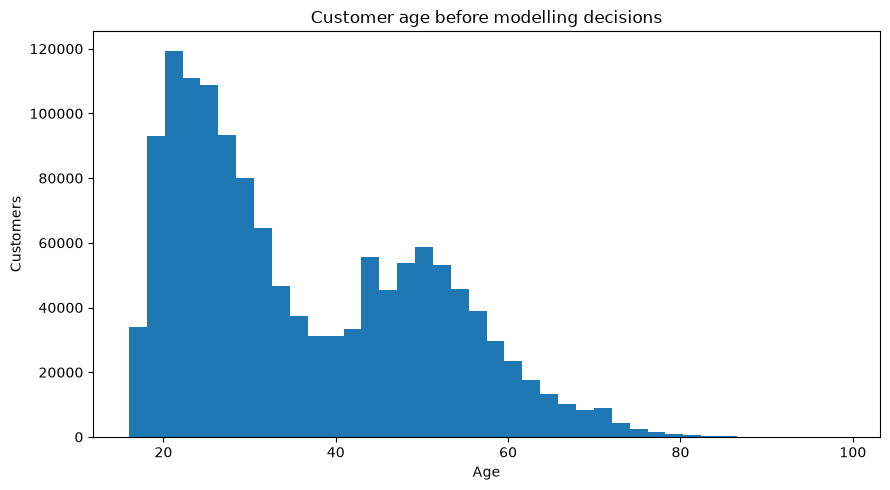

In [6]:
if "age" in customers_clean.columns:
    age = pd.to_numeric(customers_clean["age"], errors="coerce")
    customers_clean["age"] = age
    q1, q3 = age.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_iqr = q1 - 1.5 * iqr
    upper_iqr = q3 + 1.5 * iqr

    customers_clean["age_missing_flag"] = age.isna()
    customers_clean["age_iqr_extreme_flag"] = (age < lower_iqr) | (age > upper_iqr)

    age_audit = pd.DataFrame({
        "metric": ["missing_age", "missing_age_pct", "q1", "q3", "iqr", "iqr_lower_observation_bound", "iqr_upper_observation_bound", "iqr_extreme_count"],
        "value": [age.isna().sum(), age.isna().mean()*100, q1, q3, iqr, lower_iqr, upper_iqr, customers_clean["age_iqr_extreme_flag"].sum()]
    })
    display(age_audit)
    age_audit.to_csv(TABLE_DIR / "03_age_audit.csv", index=False)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(age.dropna(), bins=40)
    ax.set_xlabel("Age")
    ax.set_ylabel("Customers")
    ax.set_title("Customer age before modelling decisions")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "01_age_distribution_cleaning_stage.png", dpi=160, bbox_inches="tight")
    plt.show()

In [7]:
customer_before = len(customers_clean)
customers_clean = customers_clean[customers_clean["customer_id"].notna()].copy()

if customers_clean["customer_id"].duplicated().any():
    raise ValueError("duplicate customer_id vẫn tồn tại — cần điều tra trước khi tiếp tục")

customer_after = len(customers_clean)
customer_cleaning_summary = pd.DataFrame({
    "metric": ["rows_before", "rows_after", "rows_removed", "pct_removed"],
    "value": [customer_before, customer_after, customer_before-customer_after, (customer_before-customer_after)/customer_before*100]
})
display(customer_cleaning_summary)
customer_cleaning_summary.to_csv(TABLE_DIR / "04_customer_cleaning_summary.csv", index=False)

,metric,value
0,rows_before,1371980.0
1,rows_after,1371980.0
2,rows_removed,0.0
3,pct_removed,0.0


## 4. Cleaning `articles.csv`
- key phải hợp lệ;
- textual metadata được strip;
- missing category không tự điền;
- article metadata thiếu không làm mất transaction RFM nếu transaction vẫn hợp lệ.

In [8]:
article_key_audit = pd.DataFrame({
    "metric": ["rows", "missing_article_id", "duplicate_article_id_rows", "unique_article_id"],
    "value": [
        len(articles_raw),
        articles_raw["article_id"].isna().sum(),
        articles_raw["article_id"].duplicated(keep=False).sum(),
        articles_raw["article_id"].nunique(dropna=True)
    ]
})
display(article_key_audit)
article_key_audit.to_csv(TABLE_DIR / "05_article_key_audit.csv", index=False)

articles_clean = articles_raw.copy()
articles_clean["article_id"] = articles_clean["article_id"].astype("string").str.strip().replace("", pd.NA)
text_cols = [c for c in articles_clean.select_dtypes(include=["object", "string"]).columns if c != "article_id"]
for c in text_cols:
    articles_clean[c] = articles_clean[c].astype("string").str.strip().replace("", pd.NA)

article_before = len(articles_clean)
articles_clean = articles_clean[articles_clean["article_id"].notna()].copy()
if articles_clean["article_id"].duplicated().any():
    raise ValueError("duplicate article_id vẫn tồn tại — cần điều tra trước khi tiếp tục")
article_after = len(articles_clean)

article_cleaning_summary = pd.DataFrame({
    "metric": ["rows_before", "rows_after", "rows_removed", "pct_removed"],
    "value": [article_before, article_after, article_before-article_after, (article_before-article_after)/article_before*100]
})
display(article_cleaning_summary)
article_cleaning_summary.to_csv(TABLE_DIR / "06_article_cleaning_summary.csv", index=False)

,metric,value
0,rows,105542
1,missing_article_id,0
2,duplicate_article_id_rows,0
3,unique_article_id,105542


,metric,value
0,rows_before,105542.0
1,rows_after,105542.0
2,rows_removed,0.0
3,pct_removed,0.0


## 5. Transaction cleaning bằng DuckDB

Dùng DuckDB vì transaction table rất lớn. Chỉ loại row không thể dùng hợp lệ cho segmentation: date invalid, customer_id missing, price invalid/non-positive. `article_id` missing được flag thay vì xóa.

In [9]:
# Nếu chưa cài, bỏ comment dòng sau và chạy một lần:
# %pip install duckdb pyarrow

import duckdb
con = duckdb.connect()
con.execute("SET max_memory = '2.5GB'")
con.execute("SET preserve_insertion_order = false")

tx_path = TRANSACTIONS_PATH.as_posix()
tx_source_sql = f"""
SELECT
    TRY_CAST(t_dat AS DATE) AS t_dat,
    NULLIF(TRIM(customer_id), '') AS customer_id,
    NULLIF(TRIM(article_id), '') AS article_id,
    TRY_CAST(price AS DOUBLE) AS price,
    TRY_CAST(sales_channel_id AS INTEGER) AS sales_channel_id
FROM read_csv('{tx_path}', header=true, all_varchar=true)
"""

tx_audit = con.execute(f"""
WITH tx AS ({tx_source_sql})
SELECT
    COUNT(*) AS rows_total,
    SUM(CASE WHEN t_dat IS NULL THEN 1 ELSE 0 END) AS invalid_date_rows,
    SUM(CASE WHEN customer_id IS NULL THEN 1 ELSE 0 END) AS missing_customer_rows,
    SUM(CASE WHEN article_id IS NULL THEN 1 ELSE 0 END) AS missing_article_rows,
    SUM(CASE WHEN price IS NULL OR NOT isfinite(price) THEN 1 ELSE 0 END) AS missing_or_invalid_price_rows,
    SUM(CASE WHEN price IS NOT NULL AND isfinite(price) AND price <= 0 THEN 1 ELSE 0 END) AS nonpositive_price_rows,
    SUM(CASE WHEN sales_channel_id IS NULL THEN 1 ELSE 0 END) AS missing_channel_rows,
    MIN(t_dat) AS min_date,
    MAX(t_dat) AS max_date,
    MIN(CASE WHEN price > 0 THEN price END) AS min_price,
    MAX(price) AS max_price
FROM tx
""").df()

print("DuckDB initialized with safe 2.5GB memory limit.")
display(tx_audit)
tx_audit.to_csv(TABLE_DIR / "07_transaction_invalid_audit.csv", index=False)

DuckDB initialized with safe 2.5GB memory limit.


## 6. Duplicate transaction audit — **không xóa**
Đếm multiplicity của cùng `customer_id + article_id + t_dat + price + sales_channel_id`. Nếu lặp, vẫn giữ vì dataset không có quantity.

In [ ]:
duplicate_tx_audit = con.execute(f"""
WITH tx AS ({tx_source_sql}),
grp AS (
    SELECT customer_id, article_id, t_dat, price, sales_channel_id, COUNT(*) AS multiplicity
    FROM tx
    GROUP BY ALL
)
SELECT
    SUM(CASE WHEN multiplicity > 1 THEN 1 ELSE 0 END) AS duplicated_unique_patterns,
    SUM(CASE WHEN multiplicity > 1 THEN multiplicity ELSE 0 END) AS rows_in_duplicated_patterns,
    MAX(multiplicity) AS max_multiplicity
FROM grp
""").df()

display(duplicate_tx_audit)
duplicate_tx_audit.to_csv(TABLE_DIR / "08_transaction_duplicate_audit.csv", index=False)

## 7. Price outlier audit — giữ extreme positive values
Không dùng IQR để xóa transaction giá cao. Extreme spending có thể chính là tín hiệu high-value customer.

In [ ]:
price_quantiles = con.execute(f"""
WITH tx AS ({tx_source_sql})
SELECT
    quantile_cont(price, 0.00) AS p00,
    quantile_cont(price, 0.01) AS p01,
    quantile_cont(price, 0.05) AS p05,
    quantile_cont(price, 0.25) AS p25,
    quantile_cont(price, 0.50) AS p50,
    quantile_cont(price, 0.75) AS p75,
    quantile_cont(price, 0.95) AS p95,
    quantile_cont(price, 0.99) AS p99,
    quantile_cont(price, 0.999) AS p999,
    quantile_cont(price, 1.00) AS p100
FROM tx
WHERE price IS NOT NULL AND price > 0
""").df().T.reset_index()
price_quantiles.columns = ["quantile", "price"]
display(price_quantiles)
price_quantiles.to_csv(TABLE_DIR / "09_price_quantiles.csv", index=False)

price_sample = con.execute(f"""
WITH tx AS ({tx_source_sql})
SELECT price
FROM tx
WHERE price IS NOT NULL AND price > 0
USING SAMPLE 200000 ROWS
""").df()["price"]

p99 = price_sample.quantile(.99)
plot_price = price_sample[price_sample <= p99]
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(plot_price, bins=50)
ax.set_xlabel("Price")
ax.set_ylabel("Sampled transaction rows")
ax.set_title("Price distribution — visualization clipped at sample p99")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_price_distribution_p99.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(np.log1p(price_sample), bins=50)
ax.set_xlabel("log1p(price)")
ax.set_ylabel("Sampled transaction rows")
ax.set_title("Price distribution on log scale — diagnostic only")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_price_distribution_log.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Referential integrity
Không inner-join rồi âm thầm mất transaction. Đo coverage của customer/article master trước.

In [ ]:
con.register("customers_dim", customers_clean[["customer_id"]])
con.register("articles_dim", articles_clean[["article_id"]])

referential_audit = con.execute(f"""
WITH tx AS ({tx_source_sql})
SELECT
    COUNT(*) AS tx_rows,
    AVG(CASE WHEN c.customer_id IS NOT NULL THEN 1.0 ELSE 0.0 END) * 100 AS customer_master_coverage_pct,
    AVG(CASE WHEN a.article_id IS NOT NULL THEN 1.0 ELSE 0.0 END) * 100 AS article_master_coverage_pct
FROM tx
LEFT JOIN customers_dim c USING (customer_id)
LEFT JOIN articles_dim a USING (article_id)
""").df()

display(referential_audit)
referential_audit.to_csv(TABLE_DIR / "10_referential_integrity.csv", index=False)

## 9. Tạo `transactions_clean.parquet`

**Giữ:** duplicate, extreme positive price, missing article metadata, channel code chưa map.

**Loại:** invalid date, missing customer_id, invalid/non-positive price.

In [ ]:
TRANSACTIONS_CLEAN_PATH = PROCESSED_DIR / "transactions_clean.parquet"

clean_tx_sql = f"""
WITH tx AS ({tx_source_sql})
SELECT
    t_dat,
    customer_id,
    article_id,
    price,
    sales_channel_id,
    article_id IS NULL AS article_missing_flag,
    sales_channel_id IS NULL AS channel_missing_flag
FROM tx
WHERE
    t_dat IS NOT NULL
    AND customer_id IS NOT NULL
    AND price IS NOT NULL
    AND isfinite(price)
    AND price > 0
"""

con.execute(f"""
COPY ({clean_tx_sql})
TO '{TRANSACTIONS_CLEAN_PATH.as_posix()}'
(FORMAT PARQUET, COMPRESSION ZSTD)
""")
print("Saved:", TRANSACTIONS_CLEAN_PATH)

## 10. Before/After transaction summary

In [ ]:
before_after_tx = con.execute(f"""
WITH raw_tx AS ({tx_source_sql}), clean_tx AS ({clean_tx_sql})
SELECT 'before' AS stage, COUNT(*) AS rows, COUNT(DISTINCT customer_id) AS customers,
       COUNT(DISTINCT article_id) AS articles, MIN(t_dat) AS min_date, MAX(t_dat) AS max_date,
       AVG(price) AS mean_price
FROM raw_tx
UNION ALL
SELECT 'after' AS stage, COUNT(*) AS rows, COUNT(DISTINCT customer_id) AS customers,
       COUNT(DISTINCT article_id) AS articles, MIN(t_dat) AS min_date, MAX(t_dat) AS max_date,
       AVG(price) AS mean_price
FROM clean_tx
""").df()

display(before_after_tx)
before_after_tx.to_csv(TABLE_DIR / "11_transactions_before_after.csv", index=False)

before_rows = before_after_tx.loc[before_after_tx["stage"]=="before", "rows"].iloc[0]
after_rows = before_after_tx.loc[before_after_tx["stage"]=="after", "rows"].iloc[0]
removal_summary = pd.DataFrame({
    "metric": ["rows_removed", "pct_rows_removed"],
    "value": [before_rows-after_rows, (before_rows-after_rows)/before_rows*100]
})
display(removal_summary)
removal_summary.to_csv(TABLE_DIR / "12_transaction_removal_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(before_after_tx["stage"], before_after_tx["rows"])
ax.set_ylabel("Transaction rows")
ax.set_title("Transaction rows before vs after cleaning")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_transactions_before_after.png", dpi=160, bbox_inches="tight")
plt.show()

## 11. Export cleaned customer/article tables
Không impute missing metadata ở Phase 2.

In [ ]:
CUSTOMERS_CLEAN_PATH = PROCESSED_DIR / "customers_clean.parquet"
ARTICLES_CLEAN_PATH = PROCESSED_DIR / "articles_clean.parquet"
customers_clean.to_parquet(CUSTOMERS_CLEAN_PATH, index=False)
articles_clean.to_parquet(ARTICLES_CLEAN_PATH, index=False)
print("Saved:", CUSTOMERS_CLEAN_PATH)
print("Saved:", ARTICLES_CLEAN_PATH)

## 12. Validation sau cleaning
Post-clean phải không còn invalid date, missing customer key hoặc invalid/non-positive price.

In [ ]:
validation = con.execute(f"""
WITH tx AS (SELECT * FROM read_parquet('{TRANSACTIONS_CLEAN_PATH.as_posix()}'))
SELECT
    COUNT(*) AS rows,
    SUM(CASE WHEN t_dat IS NULL THEN 1 ELSE 0 END) AS invalid_date_rows,
    SUM(CASE WHEN customer_id IS NULL THEN 1 ELSE 0 END) AS missing_customer_rows,
    SUM(CASE WHEN price IS NULL OR price <= 0 OR NOT isfinite(price) THEN 1 ELSE 0 END) AS invalid_price_rows,
    MIN(t_dat) AS min_date,
    MAX(t_dat) AS max_date,
    MIN(price) AS min_price,
    MAX(price) AS max_price
FROM tx
""").df()

display(validation)
validation.to_csv(TABLE_DIR / "13_post_clean_validation.csv", index=False)


assert validation.loc[0, "invalid_date_rows"] == 0
assert validation.loc[0, "missing_customer_rows"] == 0
assert validation.loc[0, "invalid_price_rows"] == 0
assert not customers_clean["customer_id"].duplicated().any()
assert not articles_clean["article_id"].duplicated().any()
print("Core Phase 2 validation: PASSED")

## 13. Cleaning Decision Log
Bảng này có thể đưa trực tiếp vào báo cáo.

In [ ]:
audit_row = tx_audit.iloc[0]
decision_log = pd.DataFrame([
    ["Transaction date invalid", "DROP", "Không thể sử dụng cho Recency/Frequency/temporal analysis", int(audit_row["invalid_date_rows"])],
    ["Missing customer_id", "DROP_FOR_SEGMENTATION", "Không thể aggregate theo customer", int(audit_row["missing_customer_rows"])],
    ["Missing/invalid/non-positive price", "DROP", "Không tạo Monetary hợp lệ", int(audit_row["missing_or_invalid_price_rows"] + audit_row["nonpositive_price_rows"])],
    ["Exact duplicate transactions", "KEEP", "Có thể biểu diễn multiple units; dataset không có quantity/order_id", int(duplicate_tx_audit.loc[0, "rows_in_duplicated_patterns"])],
    ["Extreme positive price", "KEEP", "Có thể là high-value behavior; xử lý skew ở modelling stage thay vì xóa", np.nan],
    ["Missing customer age", "KEEP_NULL", "Age không phải key giao dịch; imputation nếu cần sẽ được đánh giá sau", int(customers_clean["age"].isna().sum()) if "age" in customers_clean.columns else np.nan],
    ["Missing article metadata", "KEEP_NULL / FLAG", "RFM vẫn tính được; product-diversity phải xét coverage riêng", np.nan]
], columns=["issue", "decision", "reason", "affected_rows_or_records"])

display(decision_log)
decision_log.to_csv(TABLE_DIR / "14_cleaning_decision_log.csv", index=False)

## 14. Report-ready conclusion template

Sau khi chạy notebook, điền số liệu thật vào đoạn sau:

> Quá trình tiền xử lý được thực hiện theo nguyên tắc chỉ loại bỏ các bản ghi không thể sử dụng hợp lệ cho phân tích cấp khách hàng. Các transaction thiếu thời gian, thiếu `customer_id`, hoặc có `price` không hợp lệ/không dương được loại bỏ. Ngược lại, các transaction có giá trị cực trị dương được giữ lại vì chúng có thể đại diện cho hành vi high-value thực tế và là tín hiệu quan trọng đối với customer segmentation.
>
> Đặc biệt, các dòng transaction trùng hoàn toàn không bị loại bỏ tự động. Do tập dữ liệu H&M không cung cấp `quantity` và `order_id`, các dòng lặp có thể biểu diễn việc mua nhiều đơn vị của cùng sản phẩm trong cùng ngày. Việc loại bỏ các dòng này có nguy cơ làm giảm Frequency/Monetary thực tế của khách hàng.
>
> Customer và article metadata được chuẩn hóa định dạng nhưng không impute tùy tiện các giá trị thiếu. Những missing metadata được giữ lại để đánh giá theo từng feature ở giai đoạn Feature Engineering và Feature Selection.

# Điều kiện để chuyển sang Phase 3 — EDA

- [ ] `transactions_clean.parquet` tạo thành công.
- [ ] `customers_clean.parquet` tạo thành công.
- [ ] `articles_clean.parquet` tạo thành công.
- [ ] Post-clean validation PASS.
- [ ] Có bảng before/after.
- [ ] Có `cleaning_decision_log.csv`.
- [ ] Mọi row bị loại đều có rule giải thích.
- [ ] Không xóa statistical outlier chỉ vì IQR.
- [ ] Không xóa exact transaction duplicate một cách máy móc.

**Phase 3 — Exploratory Data Analysis** sẽ phân tích purchase over time, customer activity, spending, repeat purchase, product/fashion structure, customer metadata và channel behavior để tìm pattern hỗ trợ thiết kế Extended RFM.